# M6.5 · 时序/关系数据库与数据模型

> 实盘要把行情、信号、订单、成交落库，且必须支持 Point-in-Time（PIT）查询：
> 在某个历史时刻只能看到当时已经入库的数据，从存储层杜绝未来函数。

## 一、数据模型与 PIT

- **时序库**（InfluxDB/ClickHouse/DolphinDB）：高吞吐写行情与指标；
- **关系库**：账户、订单、配置等强一致数据；
- **PIT 关键**：每条观测带业务时间 `ts` 与入库时间 `ingest_ts`，
  查询时同时约束二者，延迟到达的数据不会提前可见。

下面用标准库 SQLite 模拟时序库（无需真实服务）。

## 二、PIT 读写

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from live_lab2 import storage
store = storage.PITStore()
store.upsert('A', '2026-01-01', 'close', 10, '2026-01-01')
store.upsert('A', '2026-01-02', 'close', 11, '2026-01-03')  # 延迟入库
print('asof 01-01(看不到延迟数据)=%s' % store.asof_query('A', 'close', '2026-01-01'))
print('asof 01-02(业务已到但未入库)=%s' % store.asof_query('A', 'close', '2026-01-02'))
print('asof 01-03(入库后可见)=%s' % store.asof_query('A', 'close', '2026-01-03'))
store.upsert('A', '2026-01-01', 'close', 10, '2026-01-01')
print('幂等重写后历史行数=%d' % len(store.history('A', 'close', '2026-01-03')))
store.close()

asof 01-01(看不到延迟数据)={'ts': '2026-01-01', 'value': 10.0}
asof 01-02(业务已到但未入库)={'ts': '2026-01-01', 'value': 10.0}
asof 01-03(入库后可见)={'ts': '2026-01-02', 'value': 11.0}
幂等重写后历史行数=2


## 三、可视化：PIT 时间线

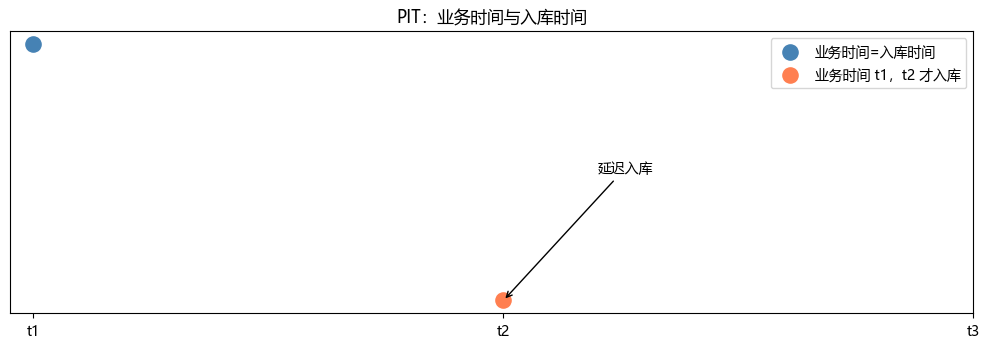

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 3.6))
days = [0, 1, 2]
ax.scatter([0], [1], s=120, color='steelblue', label='业务时间=入库时间')
ax.scatter([1], [0.6], s=120, color='coral', label='业务时间 t1，t2 才入库')
ax.annotate('延迟入库', xy=(1, 0.6), xytext=(1.2, 0.8),
            arrowprops=dict(arrowstyle='->'))
ax.set_xticks(days); ax.set_xticklabels(['t1', 't2', 't3'])
ax.set_yticks([]); ax.set_title('PIT：业务时间与入库时间'); ax.legend()
plt.tight_layout(); plt.show()

## 四、面试要点

- **PIT 为什么要同时存业务时间和入库时间？** 财报/复权等数据常有延迟或修订，只有入库时间也不晚于查询点，才能还原当时真实可见信息。
- **时序库与关系库如何分工？** 时序库高吞吐写带时间戳的行情/指标，关系库管强一致的交易与账户数据。
- **写入如何保证幂等？** 用 (code,ts,field) 作主键 upsert，重复写覆盖而非产生重复行。
- **复权因子修订如何处理？** 保留修订版本与入库时间，历史回测按当时版本 PIT 取数。

## 五、练习

1. 给 PITStore 增加字段级批量写入。
2. 实现数据修订的版本链（保留所有历史版本）。
3. 对比 SQLite 与列式时序库的写入模型。
4. 用 PIT 存储重跑一个因子并检查结果差异。